In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

# 1. Loading and checking data
- Load the supplied CSV, and check that it has the expected columns and usable values. I turn the year and month into a real date so pandas can sort and compare months.

In [3]:
df = pd.read_csv('data/Inflation Rates.csv')
df.head()

,Year,Month,Annual Average Inflation,12-Month Inflation
0,2026,September,5.44,6.76
1,2026,August,5.25,6.59
2,2026,July,5.08,6.49
3,2026,June,4.88,6.41
4,2026,May,4.66,6.68


In [6]:
df.columns

Index(['Year', 'Month', 'Annual Average Inflation', '12-Month Inflation'], dtype='str')

In [4]:
df["Year"] = pd.to_numeric(df["Year"])
df["Annual Average Inflation"] = pd.to_numeric(df["Annual Average Inflation"])
df["12-Month Inflation"] = pd.to_numeric(df["12-Month Inflation"])
df["date"] = pd.to_datetime(
    df["Month"] + " 1 " + df["Year"].astype(str),
    format="%B %d %Y"
)
df = df.sort_values("date").reset_index(drop=True)

## Handling duplicates
The dataset  has April 2019 twice: the code removes one row only if both records match exactly. It then checks that every month from the first date to the last is present. The output shows how many rows remain and the actual coverage.

In [5]:

# 1. Define the inflation columns
rates = ["Annual Average Inflation", "12-Month Inflation"]

# 2. Find duplicate dates
duplicates = df[df["date"].duplicated(keep=False)]

# 3. Check for conflicting inflation rates
conflicts = duplicates.groupby("date")[rates].nunique()
print("Conflicting inflation values:")
print(conflicts[conflicts.gt(1).any(axis=1)])

# 4. Remove duplicate dates
df = df.drop_duplicates(subset="date").reset_index(drop=True)

# 5. Check for missing inflation values
print("Missing inflation values:")
print(df[rates].isna().sum())

# 7. Check for missing months
expected = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="MS"
)

missing = expected.difference(df["date"])
print("Missing months:", missing.tolist())

# 8. Display dataset summary
print("Cleaned rows:", len(df))
print("First month:", df["date"].min().strftime("%B %Y"))
print("Latest month:", df["date"].max().strftime("%B %Y"))


Conflicting inflation values:
Empty DataFrame
Columns: [Annual Average Inflation, 12-Month Inflation]
Index: []
Missing inflation values:
Annual Average Inflation    0
12-Month Inflation          0
dtype: int64
Missing months: []
Cleaned rows: 261
First month: January 2005
Latest month: September 2026


## 2. Plotting the 12-month inflation change over time
- Plot the dataset's 12-Month Inflation values against their dates. The chart labels the rate in percent. The printed sentence compares the first and latest available rates in percentage points.

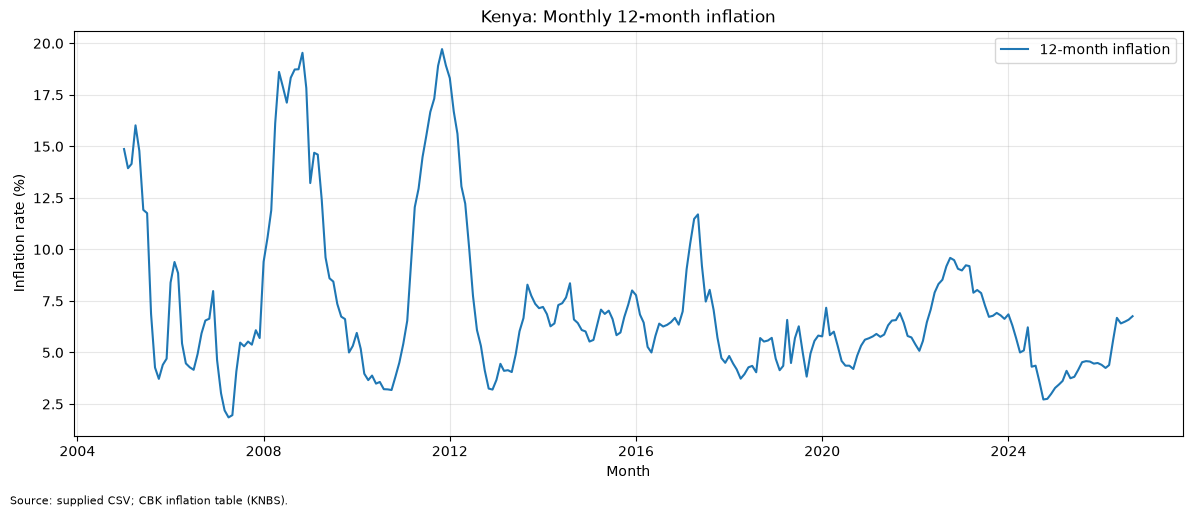

Inflation changed from 14.87% in January 2005 to 6.76% in September 2026 (-8.11 percentage points).


In [19]:

# Plot inflation over time
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["12-Month Inflation"], label="12-month inflation")

plt.title("Kenya: Monthly 12-month inflation")
plt.xlabel("Month")
plt.ylabel("Inflation rate (%)")
plt.grid(alpha=0.3)
plt.legend()

plt.figtext(0.01, -0.02, "Source: supplied CSV; CBK inflation table (KNBS).",
            ha="left", fontsize=8)
plt.tight_layout()
plt.show()

# Compare the first and latest inflation rates
first = df.iloc[0]
latest = df.iloc[-1]

change = latest["12-Month Inflation"] - first["12-Month Inflation"]

print(
    f"Inflation changed from {first['12-Month Inflation']:.2f}% "
    f"in {first['date']:%B %Y} to "
    f"{latest['12-Month Inflation']:.2f}% "
    f"in {latest['date']:%B %Y} "
    f"({change:+.2f} percentage points)."
)



## 3. Which years had the highest and lowest annual average inflation?
- In the next code cell, I select December records because the annual-average column in December represents the completed calendar year. I find the highest and lowest of those annual averages, print both, display a year-by-year table, and draw a bar chart. The file ends in September 2026, so 2026 has no December value and is not ranked as a complete year.

Highest inflation: 2008 — 16.27%
Lowest inflation: 2010 — 3.96%


,year,annual_average_pct
11,2005,9.87
23,2006,6.39
35,2007,4.27
47,2008,16.27
59,2009,9.24
71,2010,3.96
83,2011,14.02
95,2012,9.38
107,2013,5.72
119,2014,6.88


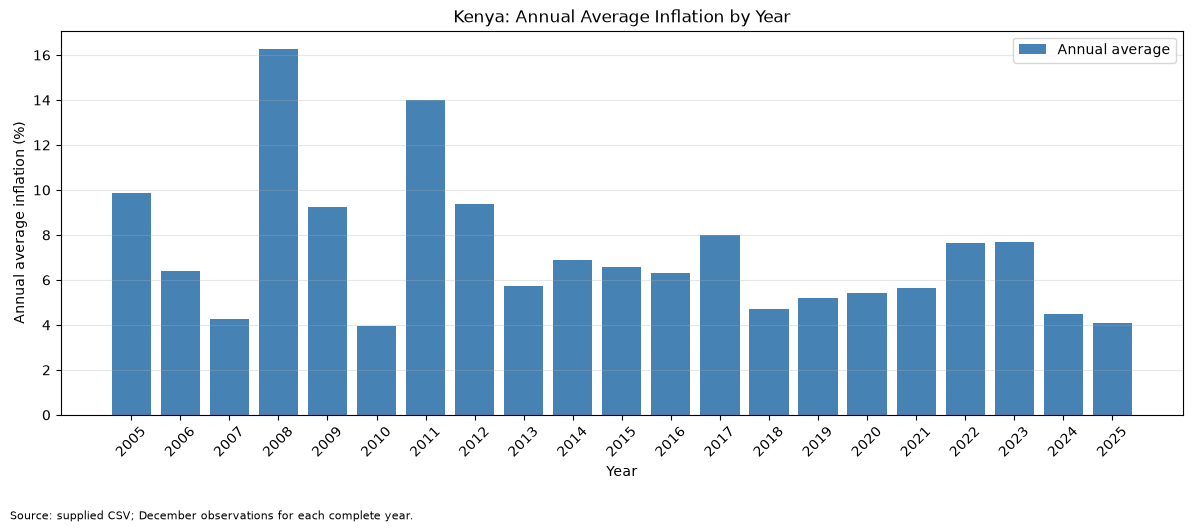

In [6]:

# Get December data to represent each year's annual average
december_data = df[df["date"].dt.month == 12]

# Keep only the year and annual average inflation columns
annual = december_data[["Year", "Annual Average Inflation"]]

# Rename columns to make them easier to use
annual = annual.rename(columns={
    "Year": "year",
    "Annual Average Inflation": "annual_average_pct"
})

# Find the years with the highest and lowest annual average inflation
highest = annual.loc[annual["annual_average_pct"].idxmax()]
lowest = annual.loc[annual["annual_average_pct"].idxmin()]

# Print the results
print(f"Highest inflation: {int(highest['year'])} — {highest['annual_average_pct']:.2f}%")
print(f"Lowest inflation: {int(lowest['year'])} — {lowest['annual_average_pct']:.2f}%")

# Display the annual inflation data rounded to 2 decimal places
display(annual.round(2))

# Create a bar chart
plt.figure(figsize=(12, 5))
plt.bar(annual["year"].astype(str), annual["annual_average_pct"],
        color="steelblue", label="Annual average")

# Add chart labels and formatting
plt.title("Kenya: Annual Average Inflation by Year")
plt.xlabel("Year")
plt.ylabel("Annual average inflation (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()

# Add the data source
plt.figtext(
    0.01, -0.05,
    "Source: supplied CSV; December observations for each complete year.",
    ha="left", fontsize=8
)

plt.tight_layout()
plt.show()


## 4. How does each annual average differ from December’s 12-month rate?
- In the next code cell, i make a table from the two measures recorded for each December. i subtract the annual average from December’s 12-month rate to show their gap in percentage points. The annual average compares average CPI across 12 months with the corresponding prior-year average; December’s 12-month rate compares December CPI with the previous December. They can differ because they compare different periods.

In [21]:
comparison = december_data[["Year", "Annual Average Inflation", "12-Month Inflation"]].copy()
comparison = comparison.rename(columns={
    "Year": "year",
    "Annual Average Inflation": "annual_average_pct",
    "12-Month Inflation": "december_12_month_pct"
})
comparison["December rate minus annual average (pp)"] = (
    comparison["december_12_month_pct"] - comparison["annual_average_pct"]
)
display(comparison.round(2))


,year,annual_average_pct,december_12_month_pct,December rate minus annual average (pp)
11,2005,9.87,4.70,-5.17
23,2006,6.39,7.98,1.59
35,2007,4.27,5.70,1.43
47,2008,16.27,17.83,1.56
59,2009,9.24,5.32,-3.92
71,2010,3.96,4.51,0.55
83,2011,14.02,18.93,4.91
95,2012,9.38,3.20,-6.18
107,2013,5.72,7.15,1.43
119,2014,6.88,6.02,-0.86


## 5. When did the 12-month rate reach its highest and lowest levels?
- In the next code cell, I locate the largest and smallest values in the 12-Month Inflation column. I print each rate with its month and year. These are extremes in the monthly year-over-year series, not month-on-month CPI changes.

In [23]:
highest_month = df.loc[df["12-Month Inflation"].idxmax()]
lowest_month = df.loc[df["12-Month Inflation"].idxmin()]
print(f"Highest: {highest_month['date']:%B %Y} — {highest_month['12-Month Inflation']:.2f}%")
print(f"Lowest:  {lowest_month['date']:%B %Y} — {lowest_month['12-Month Inflation']:.2f}%")


Highest: November 2011 — 19.72%
Lowest:  April 2007 — 1.85%


## 6. When did inflation accelerate or slow?
- In the next code cell, I use diff() to subtract each month’s 12-month rate from the previous month’s rate. I list the five biggest increases and decreases, then plot every monthly change: orange bars show acceleration and green bars show slowing. Finally, I mark local highs and lows, where the rate changes direction compared with the month before and after. All changes are percentage points in the rate, not month-to-month changes in the CPI price level.

Five largest accelerations:


,date,12-Month Inflation,rate_change
39,2008-04-01,16.12,4.22
36,2008-01-01,9.40,3.70
12,2006-01-01,8.39,3.69
75,2011-04-01,12.05,2.86
74,2011-03-01,9.19,2.65


Five largest slowdowns:


,date,12-Month Inflation,rate_change
7,2005-08-01,6.87,-4.89
48,2009-01-01,13.22,-4.61
15,2006-04-01,5.44,-3.41
24,2007-01-01,4.63,-3.35
5,2005-06-01,11.92,-2.86


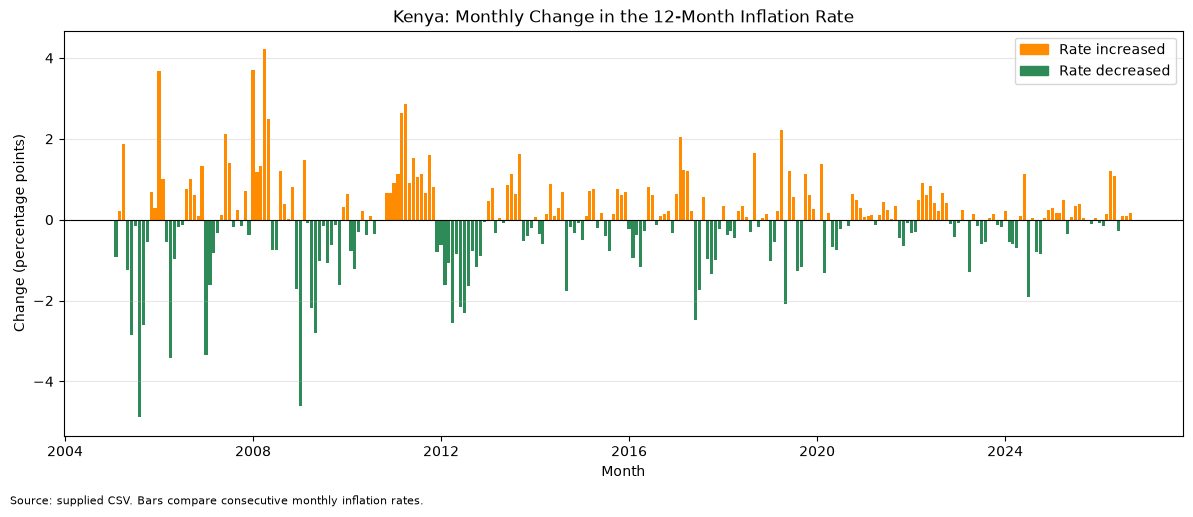

Local turning points in the 12-month inflation rate:


C:\Users\BEST\AppData\Local\Temp\ipykernel_16072\2099795740.py:85: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(turning_points.round(2))


,date,12-Month Inflation,turning_point
1,2005-02-01,13.94,Local low
3,2005-04-01,16.02,Local high
9,2005-10-01,3.72,Local low
13,2006-02-01,9.39,Local high
18,2006-07-01,4.16,Local low
...,...,...,...
250,2025-11-01,4.46,Local low
251,2025-12-01,4.49,Local high
253,2026-02-01,4.25,Local low
256,2026-05-01,6.68,Local high


In [9]:

# 1. Calculate the change in inflation rate from the previous month
df["rate_change"] = df["12-Month Inflation"].diff()

# Remove the first row because it has no previous month to compare
monthly_changes = df.dropna(subset=["rate_change"])

# 2. Display the five largest increases and decreases
print("Five largest accelerations:")
display(
    monthly_changes.nlargest(5, "rate_change")[
        ["date", "12-Month Inflation", "rate_change"]
    ].round({"12-Month Inflation": 2, "rate_change": 2})
)

print("Five largest slowdowns:")
display(
    monthly_changes.nsmallest(5, "rate_change")[
        ["date", "12-Month Inflation", "rate_change"]
    ].round({"12-Month Inflation": 2, "rate_change": 2})
)

# 3. Plot the monthly changes
# Orange means the rate increased; green means it decreased
colors = [
    "darkorange" if change >= 0 else "seagreen"
    for change in monthly_changes["rate_change"]
]

plt.figure(figsize=(12, 5))
plt.bar(monthly_changes["date"], monthly_changes["rate_change"],
        color=colors, width=25)

# Add a zero line to separate increases from decreases
plt.axhline(0, color="black", linewidth=0.8)

plt.title("Kenya: Monthly Change in the 12-Month Inflation Rate")
plt.xlabel("Month")
plt.ylabel("Change (percentage points)")
plt.grid(axis="y", alpha=0.3)

# Add a legend to explain the bar colors
plt.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color="darkorange", label="Rate increased"),
    plt.Rectangle((0, 0), 1, 1, color="seagreen", label="Rate decreased")
])

plt.figtext(
    0.01, -0.02,
    "Source: supplied CSV. Bars compare consecutive monthly inflation rates.",
    ha="left", fontsize=8
)

plt.tight_layout()
plt.show()


# 4. Find local highs and lows in the inflation rate
# Compare each month's rate with the month before and after
df["previous_rate"] = df["12-Month Inflation"].shift(1)
df["next_rate"] = df["12-Month Inflation"].shift(-1)

# A local high is higher than both neighboring months
is_high = (
    (df["12-Month Inflation"] > df["previous_rate"]) &
    (df["12-Month Inflation"] > df["next_rate"])
)

# A local low is lower than both neighboring months
is_low = (
    (df["12-Month Inflation"] < df["previous_rate"]) &
    (df["12-Month Inflation"] < df["next_rate"])
)

# Keep only the rows that are local highs or lows
turning_points = df[is_high | is_low][
    ["date", "12-Month Inflation"]
]

# Label each turning point
turning_points["turning_point"] = "Local low"
turning_points.loc[is_high, "turning_point"] = "Local high"

# Display the results
print("Local turning points in the 12-month inflation rate:")
display(turning_points.round(2))


### Purchasing power, findings, and limitations

Rising prices can reduce what a fixed amount of money buys. But inflation alone does not directly measure household welfare or purchasing power. Effects vary with income or wage growth, spending patterns, location, household size, savings, debts, and other circumstances. This notebook does not include a matching household income or wage series, so it cannot determine whether incomes kept up with prices.
Summary: the notebook reports a 2005–September 2026 monthly 12-month series, December annual-average figures for complete calendar years, December 12-month comparisons, high and low months, and the largest monthly changes in the 12-month rate.
Limitations and cleaning: the CSV does not carry source metadata, so its provenance is described cautiously; its values match the CBK table, which attributes the series to KNBS. The exact duplicate April 2019 row is removed once; no other observations are removed or interpolated. 2026 is incomplete. The CPI is a national average and may not match an individual household’s costs. The analysis describes price changes and does not establish causal effects on welfare.